# Breast Xenium input-ablation metrics

This notebook reproduces the plots in `AllDatasetMetricsSimplified.ipynb` for Breast Xenium. It compares the original full Syndri model, a full retrain, the k10 separator-token model, and query-only, neighbors-only, and no-cell-type-token ablations. Raw and SPLIT are included once from the original run. Each point is one tissue slice; Syndri uses the same 30% target-removal condition as the source notebook.


In [ ]:
from collections import OrderedDict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results")
TARGET_FRACTION = 0.30
MODEL_ROOTS = OrderedDict({
    "Full": RESULTS / "metrics",
    "Full retrain": RESULTS / "chromium_breast_xenium_full_retrain/metrics",
    "K10 separators": RESULTS / "breast_xenium_k10_separators/metrics",
    "Query only": RESULTS / "input_ablations/query_only/metrics",
    "Neighbors only": RESULTS / "input_ablations/neighbors_only/metrics",
    "No cell-type tokens": RESULTS / "input_ablations/no_cell_type_tokens/metrics",
})
MODEL_ORDER = list(MODEL_ROOTS)
CLEANED_ORDER = ["SPLIT", *MODEL_ORDER]
COUNT_ORDER = ["Raw", *CLEANED_ORDER]
COLORS = dict(zip(COUNT_ORDER, sns.color_palette("deep", len(COUNT_ORDER)).as_hex()))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
print(*[f"{model}: {root}" for model, root in MODEL_ROOTS.items()], sep="\n")


Full: /work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/metrics
Full retrain: /work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/chromium_breast_xenium_full_retrain/metrics
K10 separators: /work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/breast_xenium_k10_separators/metrics
Query only: /work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/input_ablations/query_only/metrics
Neighbors only: /work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/input_ablations/neighbors_only/metrics
No cell-type tokens: /work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/input_ablations/no_cell_type_tokens/metrics


In [2]:
def load_csv(model, family, filename):
    frames = []
    for path in sorted((MODEL_ROOTS[model] / family).glob(f"*/{filename}")):
        if not path.stat().st_size:
            continue
        try:
            frame = pd.read_csv(path, low_memory=False)
        except pd.errors.EmptyDataError:
            continue
        frame["model"], frame["slice"] = model, path.parent.name
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def valid_rows(frame):
    if "error" in frame:
        frame = frame.loc[frame["error"].fillna("").astype(str).eq("")]
    return frame.copy()


def assign_method(frame, condition_col):
    frame = frame.copy()
    condition = frame[condition_col].astype(str)
    fraction = pd.to_numeric(frame.get("target_removed_fraction"), errors="coerce")
    cleaned = (
        condition.str.startswith("cleaned_admixed_removed_frac_", na=False)
        & np.isclose(fraction, TARGET_FRACTION, rtol=0, atol=1e-8)
    )
    frame["method"] = np.select(
        [
            condition.isin(["admixed", "raw_X"]) & frame["model"].eq("Full"),
            condition.eq("SPLIT") & frame["model"].eq("Full"),
            cleaned,
        ],
        ["Raw", "SPLIT", frame["model"]],
        default="",
    )
    return frame.loc[frame["method"].ne("")].copy()


def handles(order):
    return [
        plt.Line2D([0], [0], marker="o", linestyle="", markersize=7,
                   markerfacecolor=COLORS[x], markeredgecolor=COLORS[x], label=x)
        for x in order
    ]


def metric_panels(data, value_col, metrics, order, title, zero=False):
    fig, axes = plt.subplots(2, 3, figsize=(11, 7), squeeze=False, dpi=300)
    for ax, metric in zip(axes.flat, metrics):
        subset = data.loc[data["metric"].eq(metric)]
        sns.barplot(data=subset, x="method", y=value_col, hue="method", order=order,
                    hue_order=order, palette=COLORS, legend=False, errorbar=None, ax=ax)
        sns.stripplot(data=subset, x="method", y=value_col, order=order, color="black",
                      size=3, alpha=.6, jitter=.14, ax=ax)
        if zero:
            ax.axhline(0, color="#666666", linestyle="--", linewidth=.8)
        ax.set(xlabel="", ylabel=metric)
        ax.tick_params(axis="x", rotation=32)
        ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
        ax.grid(axis="x", visible=False)
    for ax in axes.flat[len(metrics):]:
        ax.remove()
    fig.legend(handles=handles(order), loc="lower center", ncol=3,
               bbox_to_anchor=(.5, -.02), frameon=False)
    fig.suptitle(title, y=1.01)
    fig.tight_layout(rect=[0, .05, 1, 1])
    return fig


## Non-T-cell clustering metrics

Original-scale metrics, paired changes from Raw, percentage-change heatmap, and comparisons against the better of Raw and SPLIT. Davies–Bouldin is reversed for change plots so positive always means improvement.


method
Raw                    19
SPLIT                  19
Full                   19
Full retrain           19
K10 separators         19
Query only             19
Neighbors only         19
No cell-type tokens    19
Name: slice, dtype: int64


/tmp/ipykernel_3592300/1763599190.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
/tmp/ipykernel_3592300/1763599190.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
/tmp/ipykernel_3592300/1763599190.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
/tmp/ipykernel_3592300/1763599190.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
/tmp/ipykernel_3592300/1763599190.py:61: UserWarning: set_ti

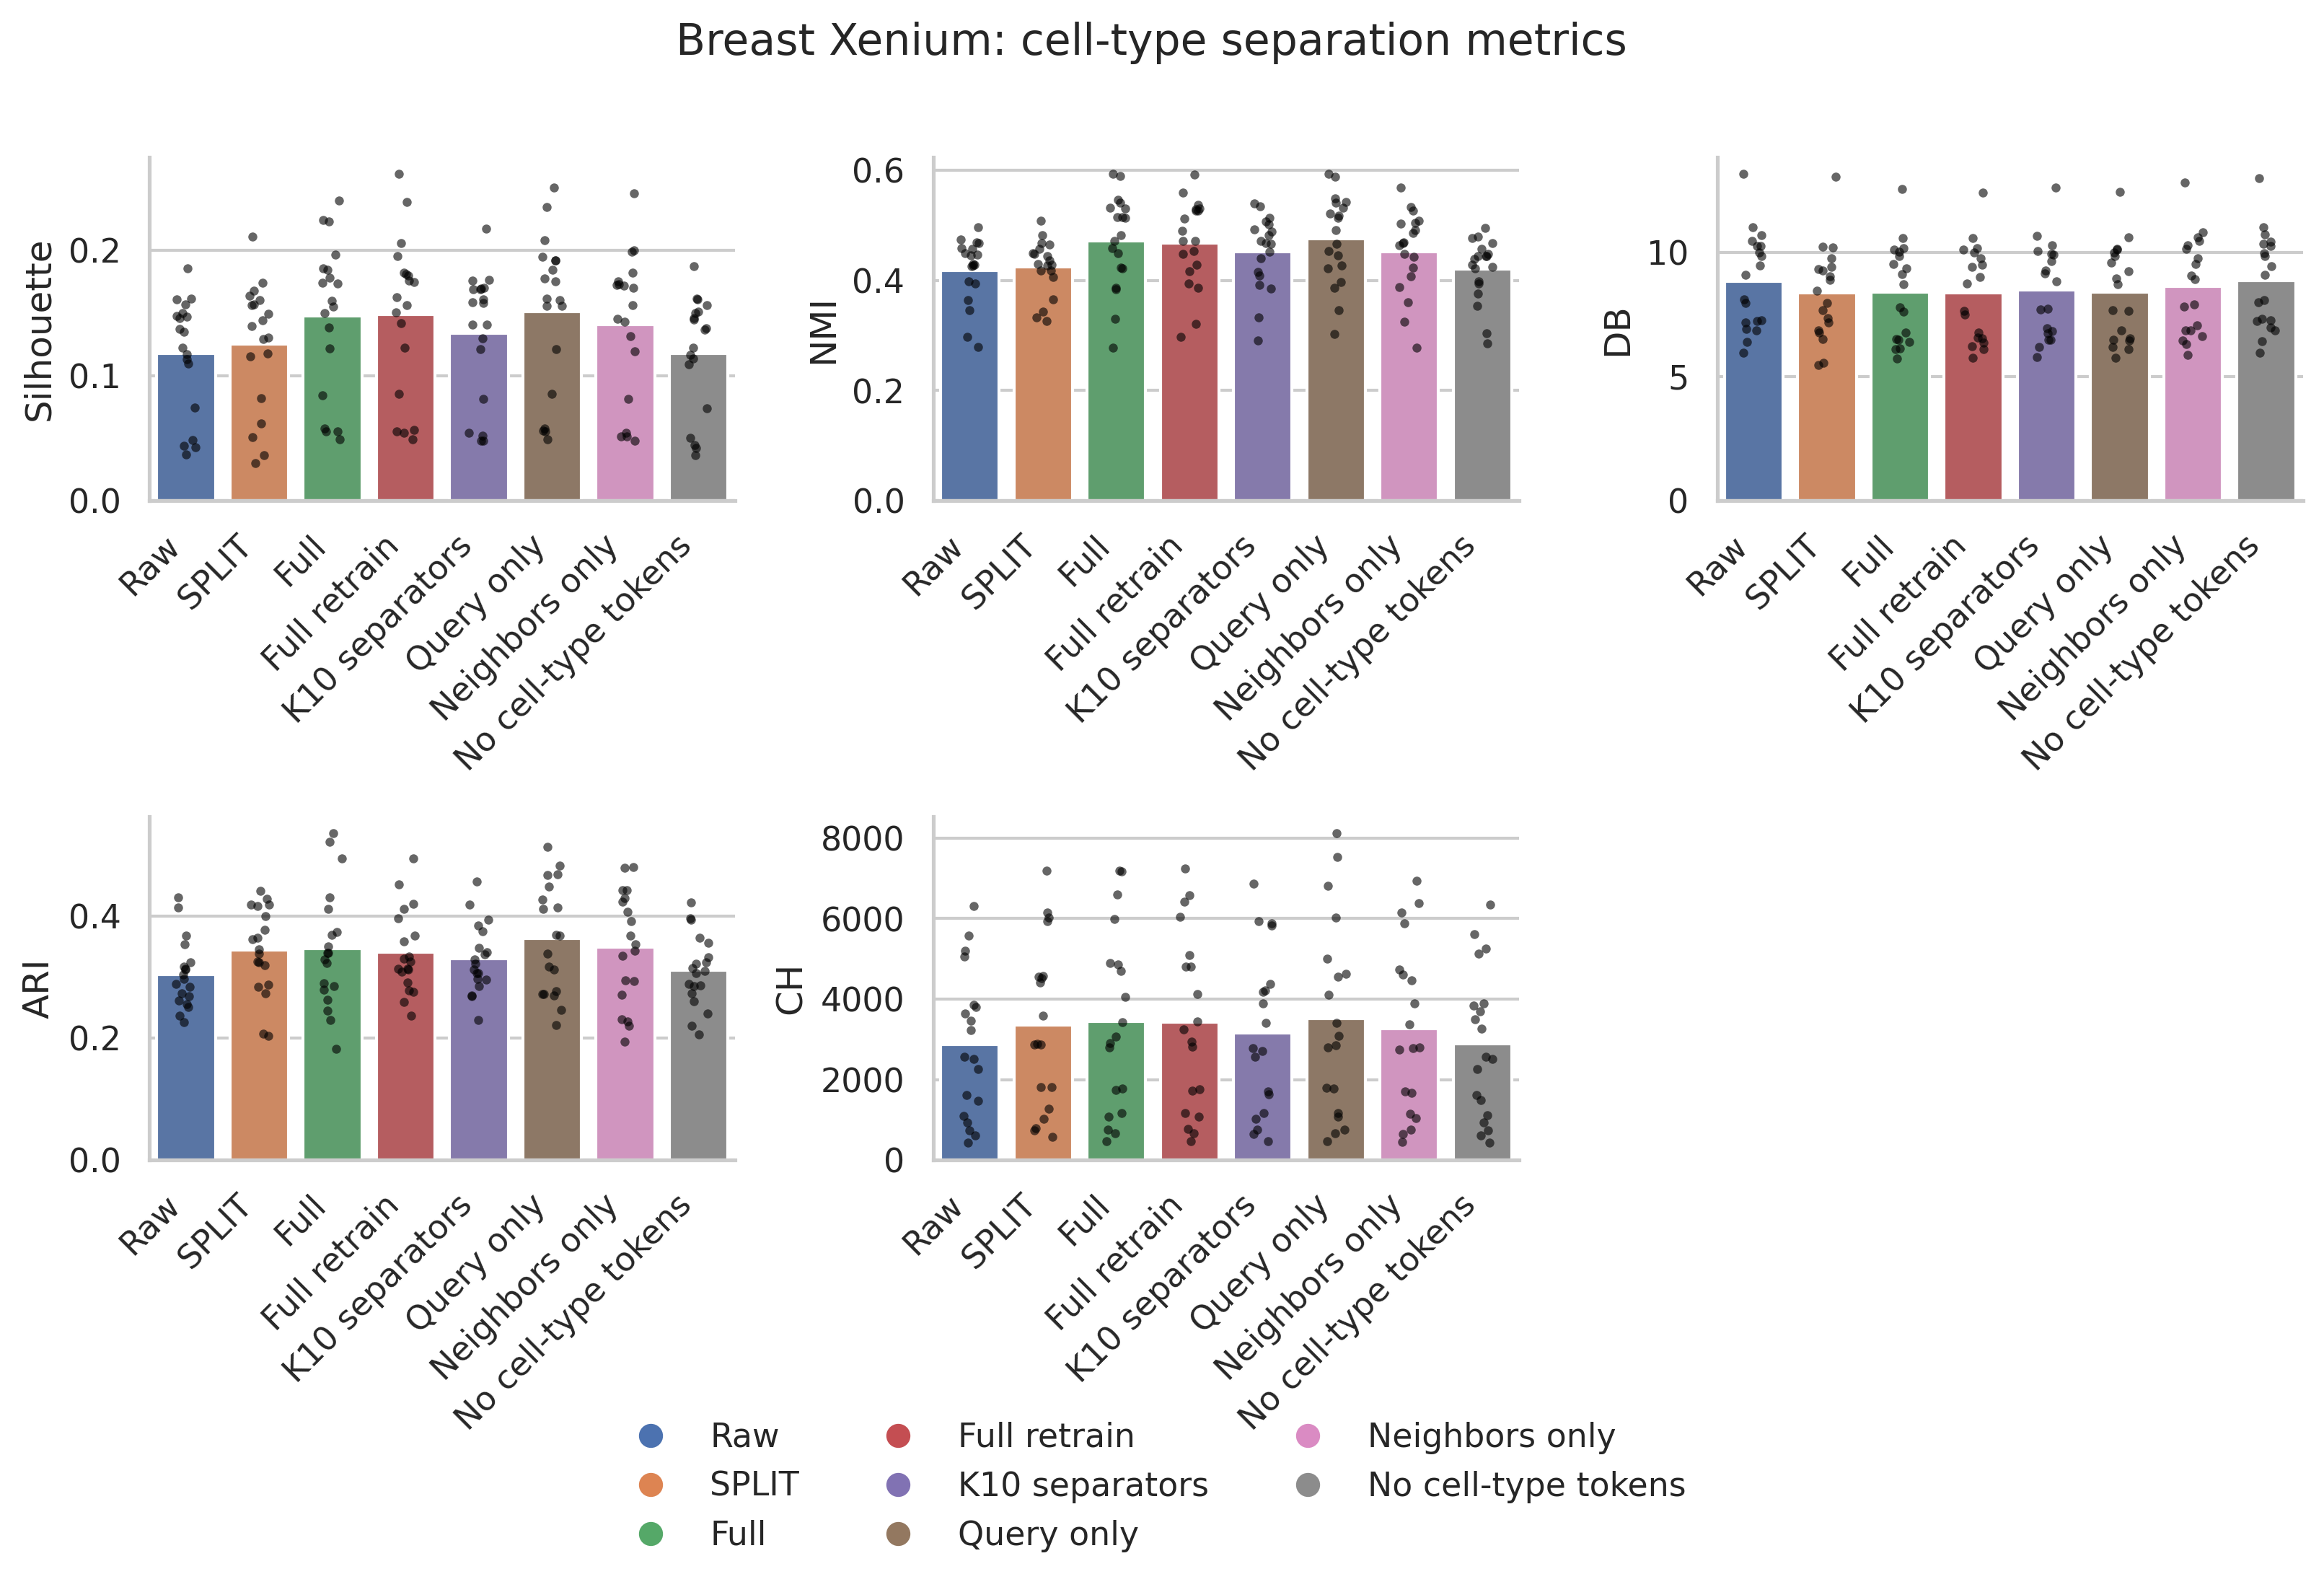

In [3]:
parts = [load_csv(model, "non_tcell", "non_tcell_metrics.csv") for model in MODEL_ORDER]
parts = [x for x in parts if not x.empty]
if len(parts) != len(MODEL_ORDER):
    raise FileNotFoundError("One or more model metric trees are missing.")
non_tcell = assign_method(valid_rows(pd.concat(parts, ignore_index=True)), "case")

METRICS = OrderedDict({
    "silhouette_score": ("Silhouette", 1),
    "calinski_harabasz": ("CH", 1),
    "davies_bouldin": ("DB", -1),
    "leiden_nmi_vs_label": ("NMI", 1),
    "leiden_adjusted_rand_vs_label": ("ARI", 1),
})
original, deltas, percents = [], [], []
for column, (metric, direction) in METRICS.items():
    values = non_tcell.groupby(["slice", "method"], observed=True)[column].mean().unstack()
    original.append(values.stack().rename("value").reset_index().assign(metric=metric))
    for method in CLEANED_ORDER:
        if "Raw" not in values or method not in values:
            continue
        deltas.append(((values[method] - values["Raw"]) * direction)
                      .rename("delta").reset_index().assign(method=method, metric=metric))
        raw = values["Raw"].replace(0, np.nan)
        percents.append((100 * direction * (values[method] - raw) / raw)
                        .rename("percent_change").reset_index().assign(method=method, metric=metric))

non_tcell_original = pd.concat(original, ignore_index=True).dropna(subset=["value"])
non_tcell_delta = pd.concat(deltas, ignore_index=True).dropna(subset=["delta"])
non_tcell_percent = (pd.concat(percents, ignore_index=True)
                     .replace([np.inf, -np.inf], np.nan).dropna(subset=["percent_change"]))
paired_percent = non_tcell_percent.pivot_table(
    index=["slice", "metric"], columns="method", values="percent_change", aggfunc="mean"
).dropna(subset=CLEANED_ORDER)
metric_order = (
    (paired_percent["Full"] - paired_percent["SPLIT"]).groupby(level="metric").mean()
    .reindex([x[0] for x in METRICS.values()]).sort_values(ascending=False, kind="stable").index.tolist()
)
print(non_tcell_original.groupby("method")["slice"].nunique().reindex(COUNT_ORDER))
metric_panels(non_tcell_original, "value", metric_order, COUNT_ORDER,
              "Breast Xenium: cell-type separation metrics")
plt.show()


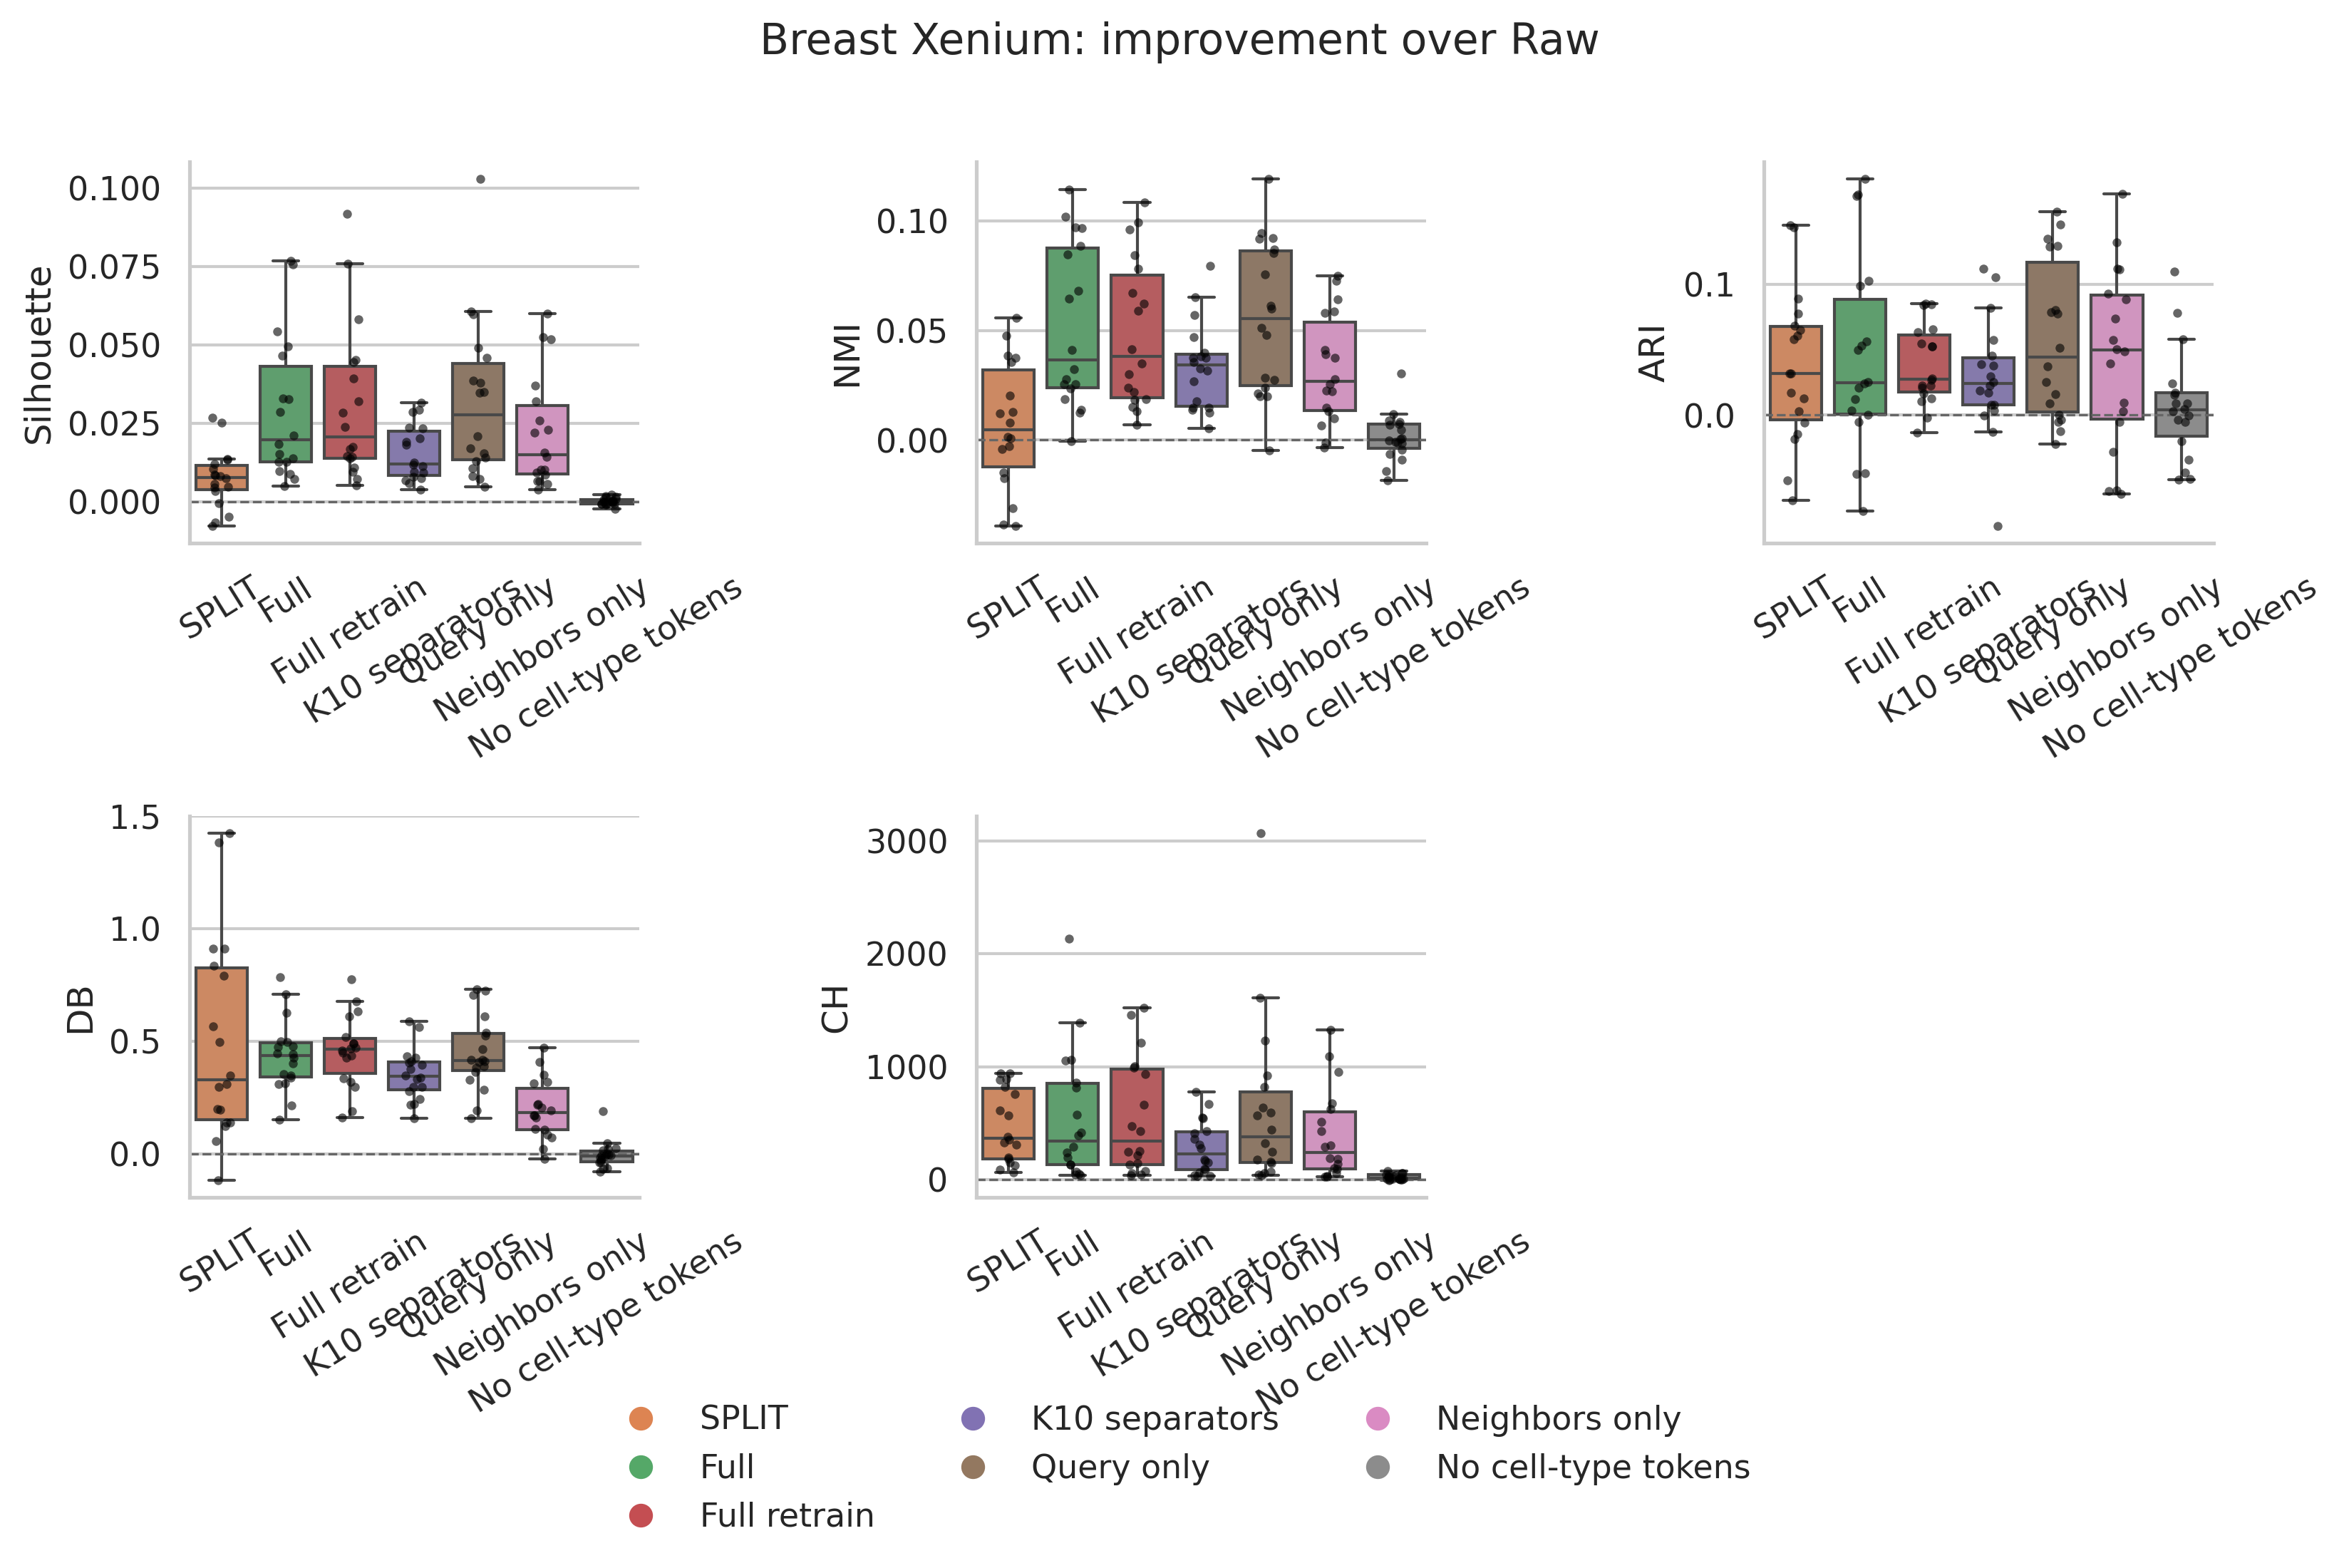

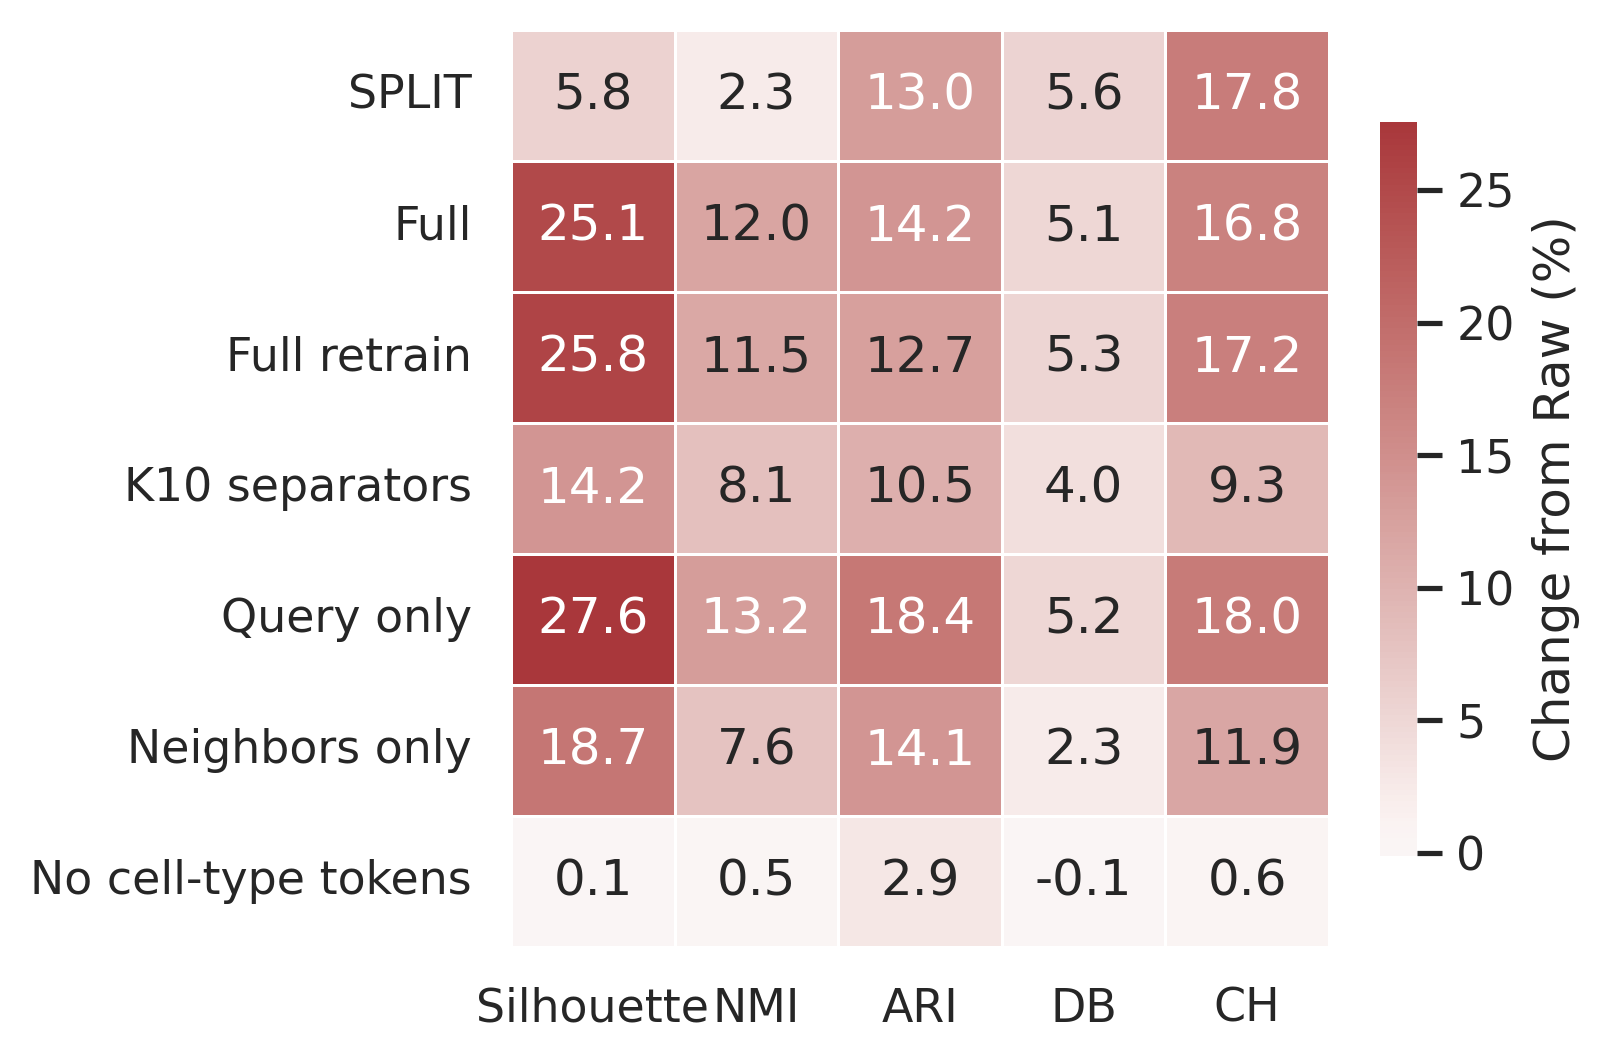

In [11]:
# Paired change from Raw.
paired_delta = non_tcell_delta.pivot_table(
    index=["slice", "metric"], columns="method", values="delta", aggfunc="mean"
).dropna(subset=CLEANED_ORDER)
delta_plot = paired_delta[CLEANED_ORDER].stack().rename("delta").reset_index()
metric_panels(delta_plot, "delta", metric_order, CLEANED_ORDER,
              "Breast Xenium: improvement over Raw", zero=True)
plt.show()

# Mean paired percentage change from Raw.
heatmap = paired_percent.groupby(level="metric").mean().T.reindex(
    index=CLEANED_ORDER, columns=metric_order
)
annotations = heatmap.map(lambda x: f"{x:.1f}" if pd.notna(x) else "")
fig, ax = plt.subplots(figsize=(5.4, 3.7), dpi=300)
sns.heatmap(heatmap, cmap="vlag", center=0, annot=annotations, fmt="",
            linewidths=.7, linecolor="white",
            cbar_kws={"label": "Change from Raw (%)", "shrink": .8}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()


### Each Syndri model versus the best alternative

For every slice, the alternative is the better of Raw and SPLIT. Dashed diagonals indicate equal values.


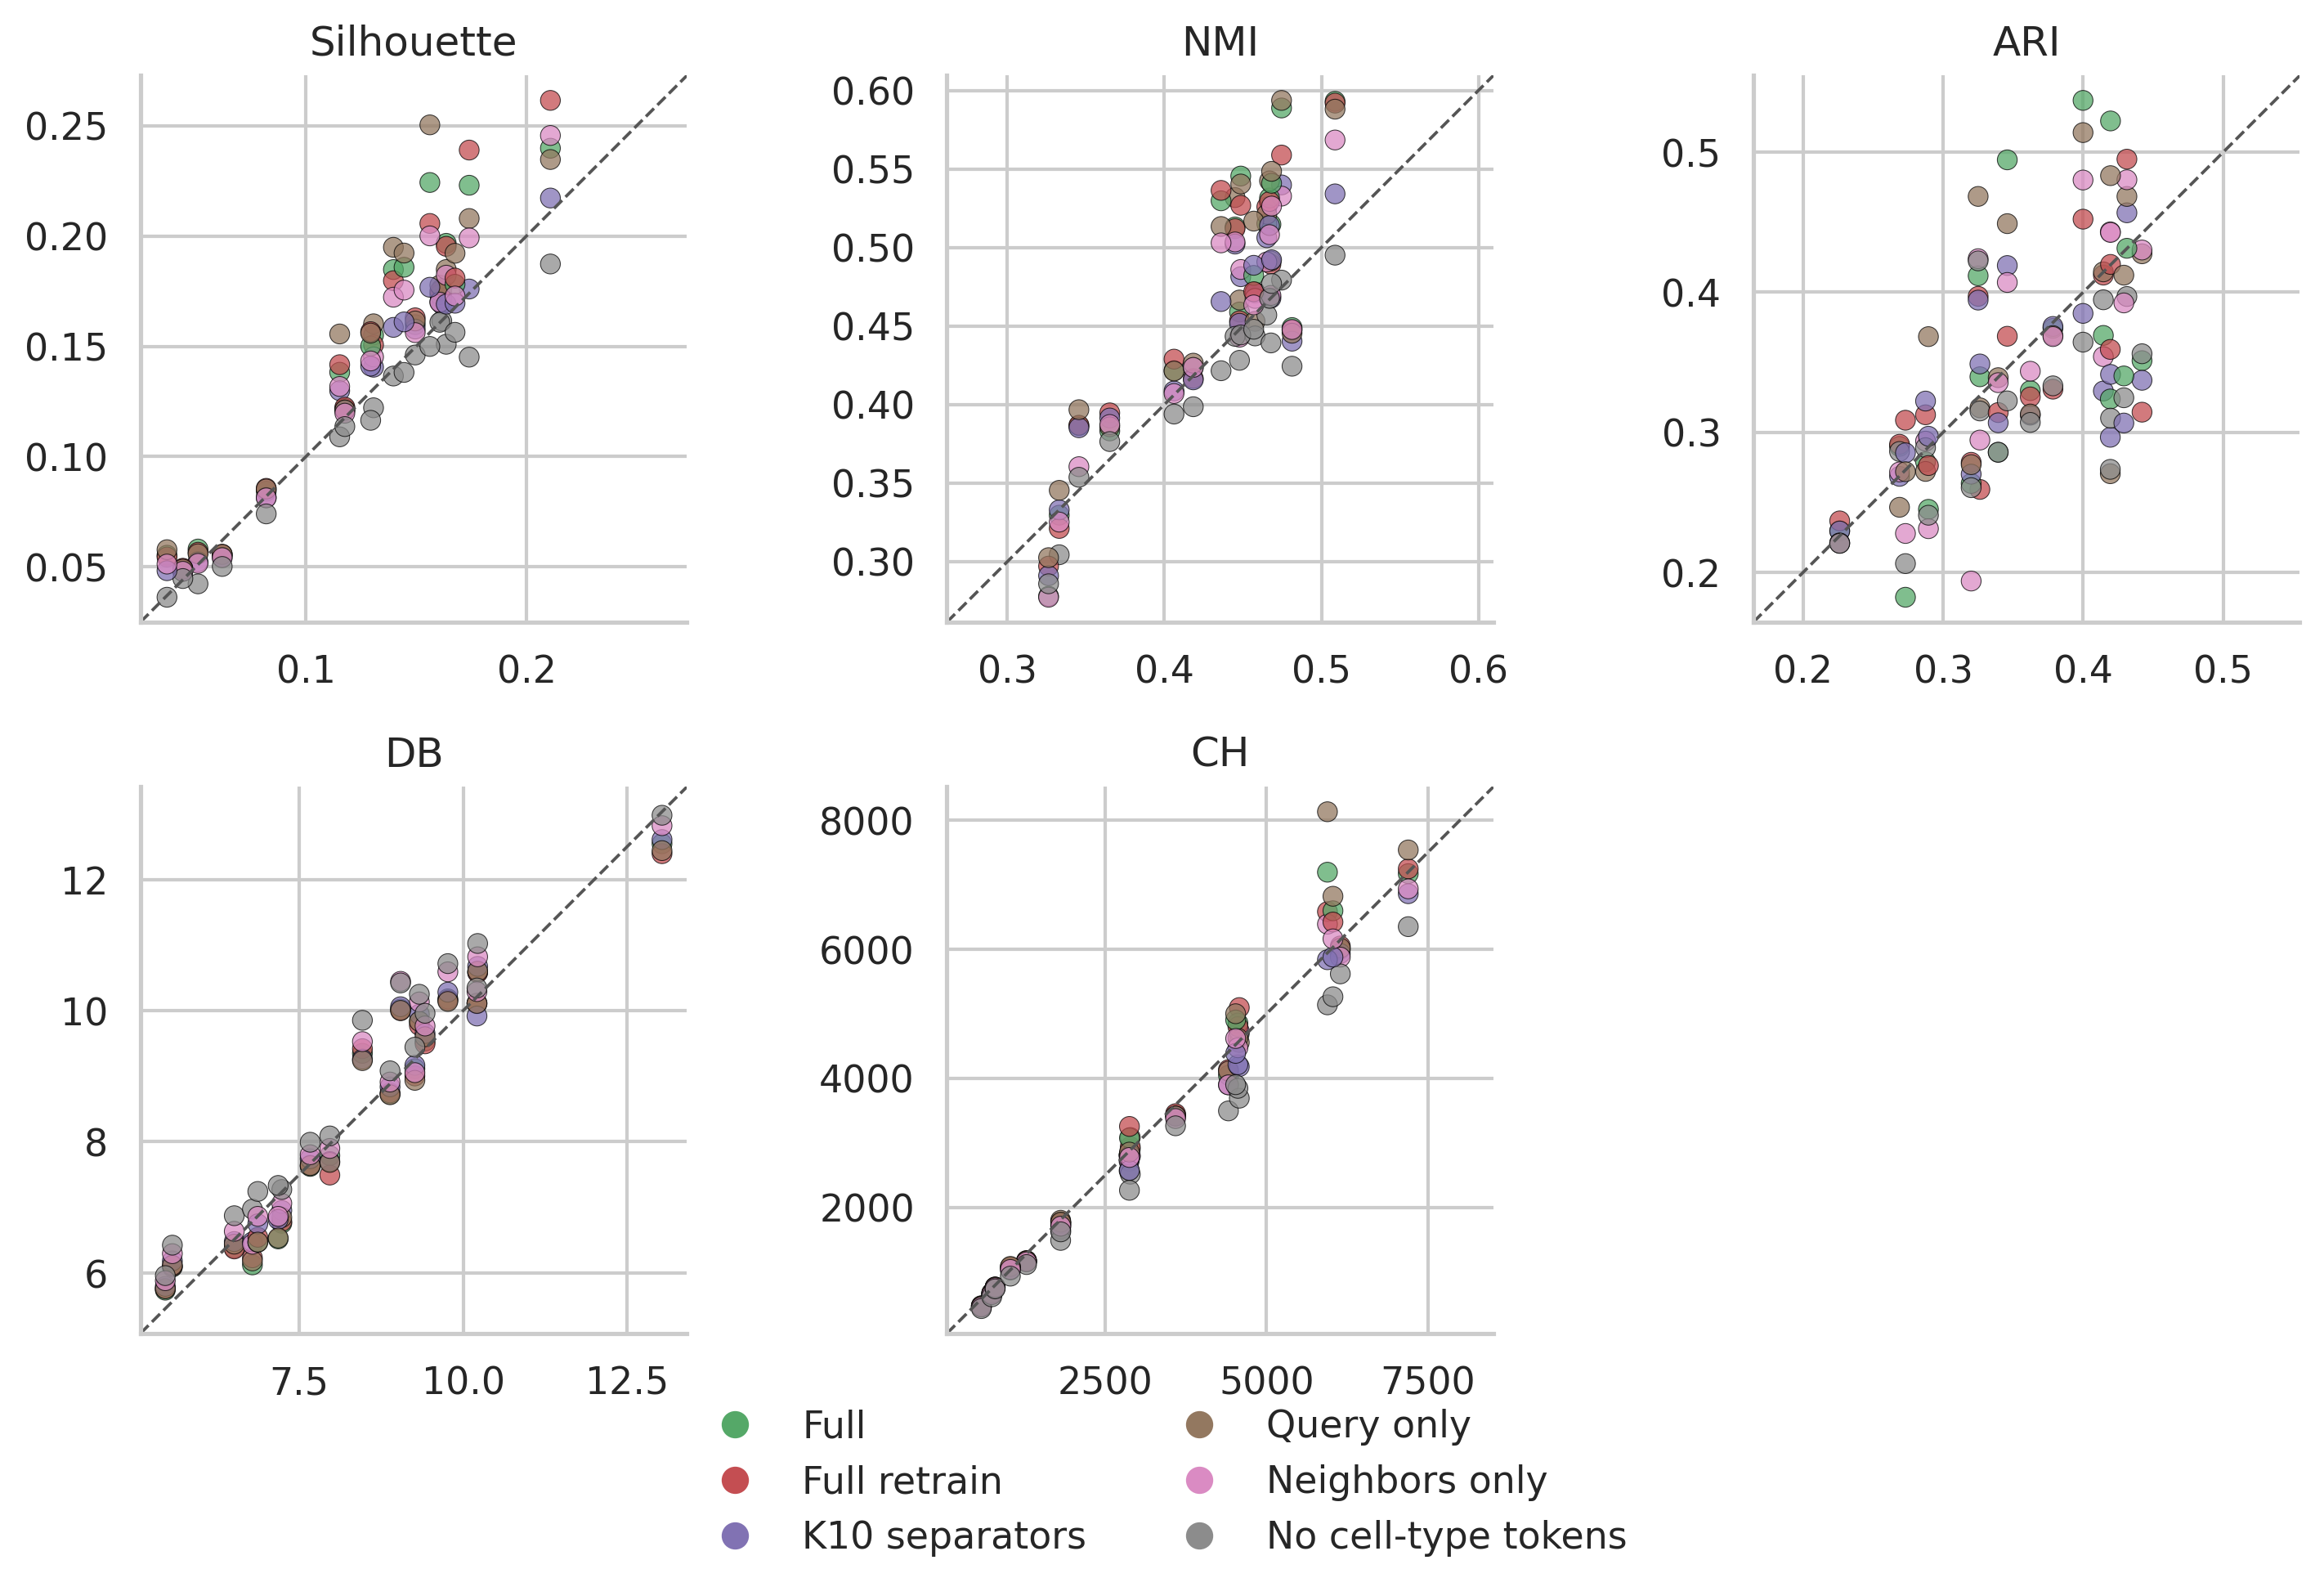

In [12]:
values = non_tcell_original.pivot_table(
    index=["slice", "metric"], columns="method", values="value", aggfunc="mean"
)
directions = pd.Series({label: direction for _, (label, direction) in METRICS.items()})
rows = []
for (slice_name, metric), row in values.iterrows():
    alternatives = row.reindex(["Raw", "SPLIT"]).dropna()
    if alternatives.empty:
        continue
    best = (alternatives * directions[metric]).idxmax()
    for model in MODEL_ORDER:
        if pd.notna(row.get(model)):
            rows.append({"slice": slice_name, "metric": metric, "model": model,
                         "best_alternative": row[best], "model_value": row[model]})
syndri_best_scatter = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 3, figsize=(10, 6.5), squeeze=False, dpi=300)
for ax, metric in zip(axes.flat, metric_order):
    subset = syndri_best_scatter.loc[syndri_best_scatter["metric"].eq(metric)]
    sns.scatterplot(data=subset, x="best_alternative", y="model_value", hue="model",
                    hue_order=MODEL_ORDER, palette={x: COLORS[x] for x in MODEL_ORDER},
                    s=34, alpha=.75, edgecolor="black", linewidth=.25, legend=False, ax=ax)
    limits = np.array([*ax.get_xlim(), *ax.get_ylim()])
    low, high = limits.min(), limits.max()
    ax.plot([low, high], [low, high], "--", color="#555555", linewidth=.9)
    ax.set(xlim=(low, high), ylim=(low, high), xlabel="", ylabel="", title=metric)
    ax.set_aspect("equal", adjustable="box")
for ax in axes.flat[len(metric_order):]:
    ax.remove()
fig.legend(handles=handles(MODEL_ORDER), loc="lower center", ncol=2,
           bbox_to_anchor=(.5, -.01), frameon=False)
fig.tight_layout(rect=[0, .08, 1, 1])
plt.show()


## T-cell metrics

Original values and paired improvements are averaged across eligible T-cell subtype comparisons within each slice.


method
Raw                    19
SPLIT                  19
Full                   19
Full retrain           19
K10 separators         19
Query only             19
Neighbors only         19
No cell-type tokens    19
Name: slice, dtype: int64


/tmp/ipykernel_3153997/1949607224.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha='right')
/tmp/ipykernel_3153997/1949607224.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha='right')


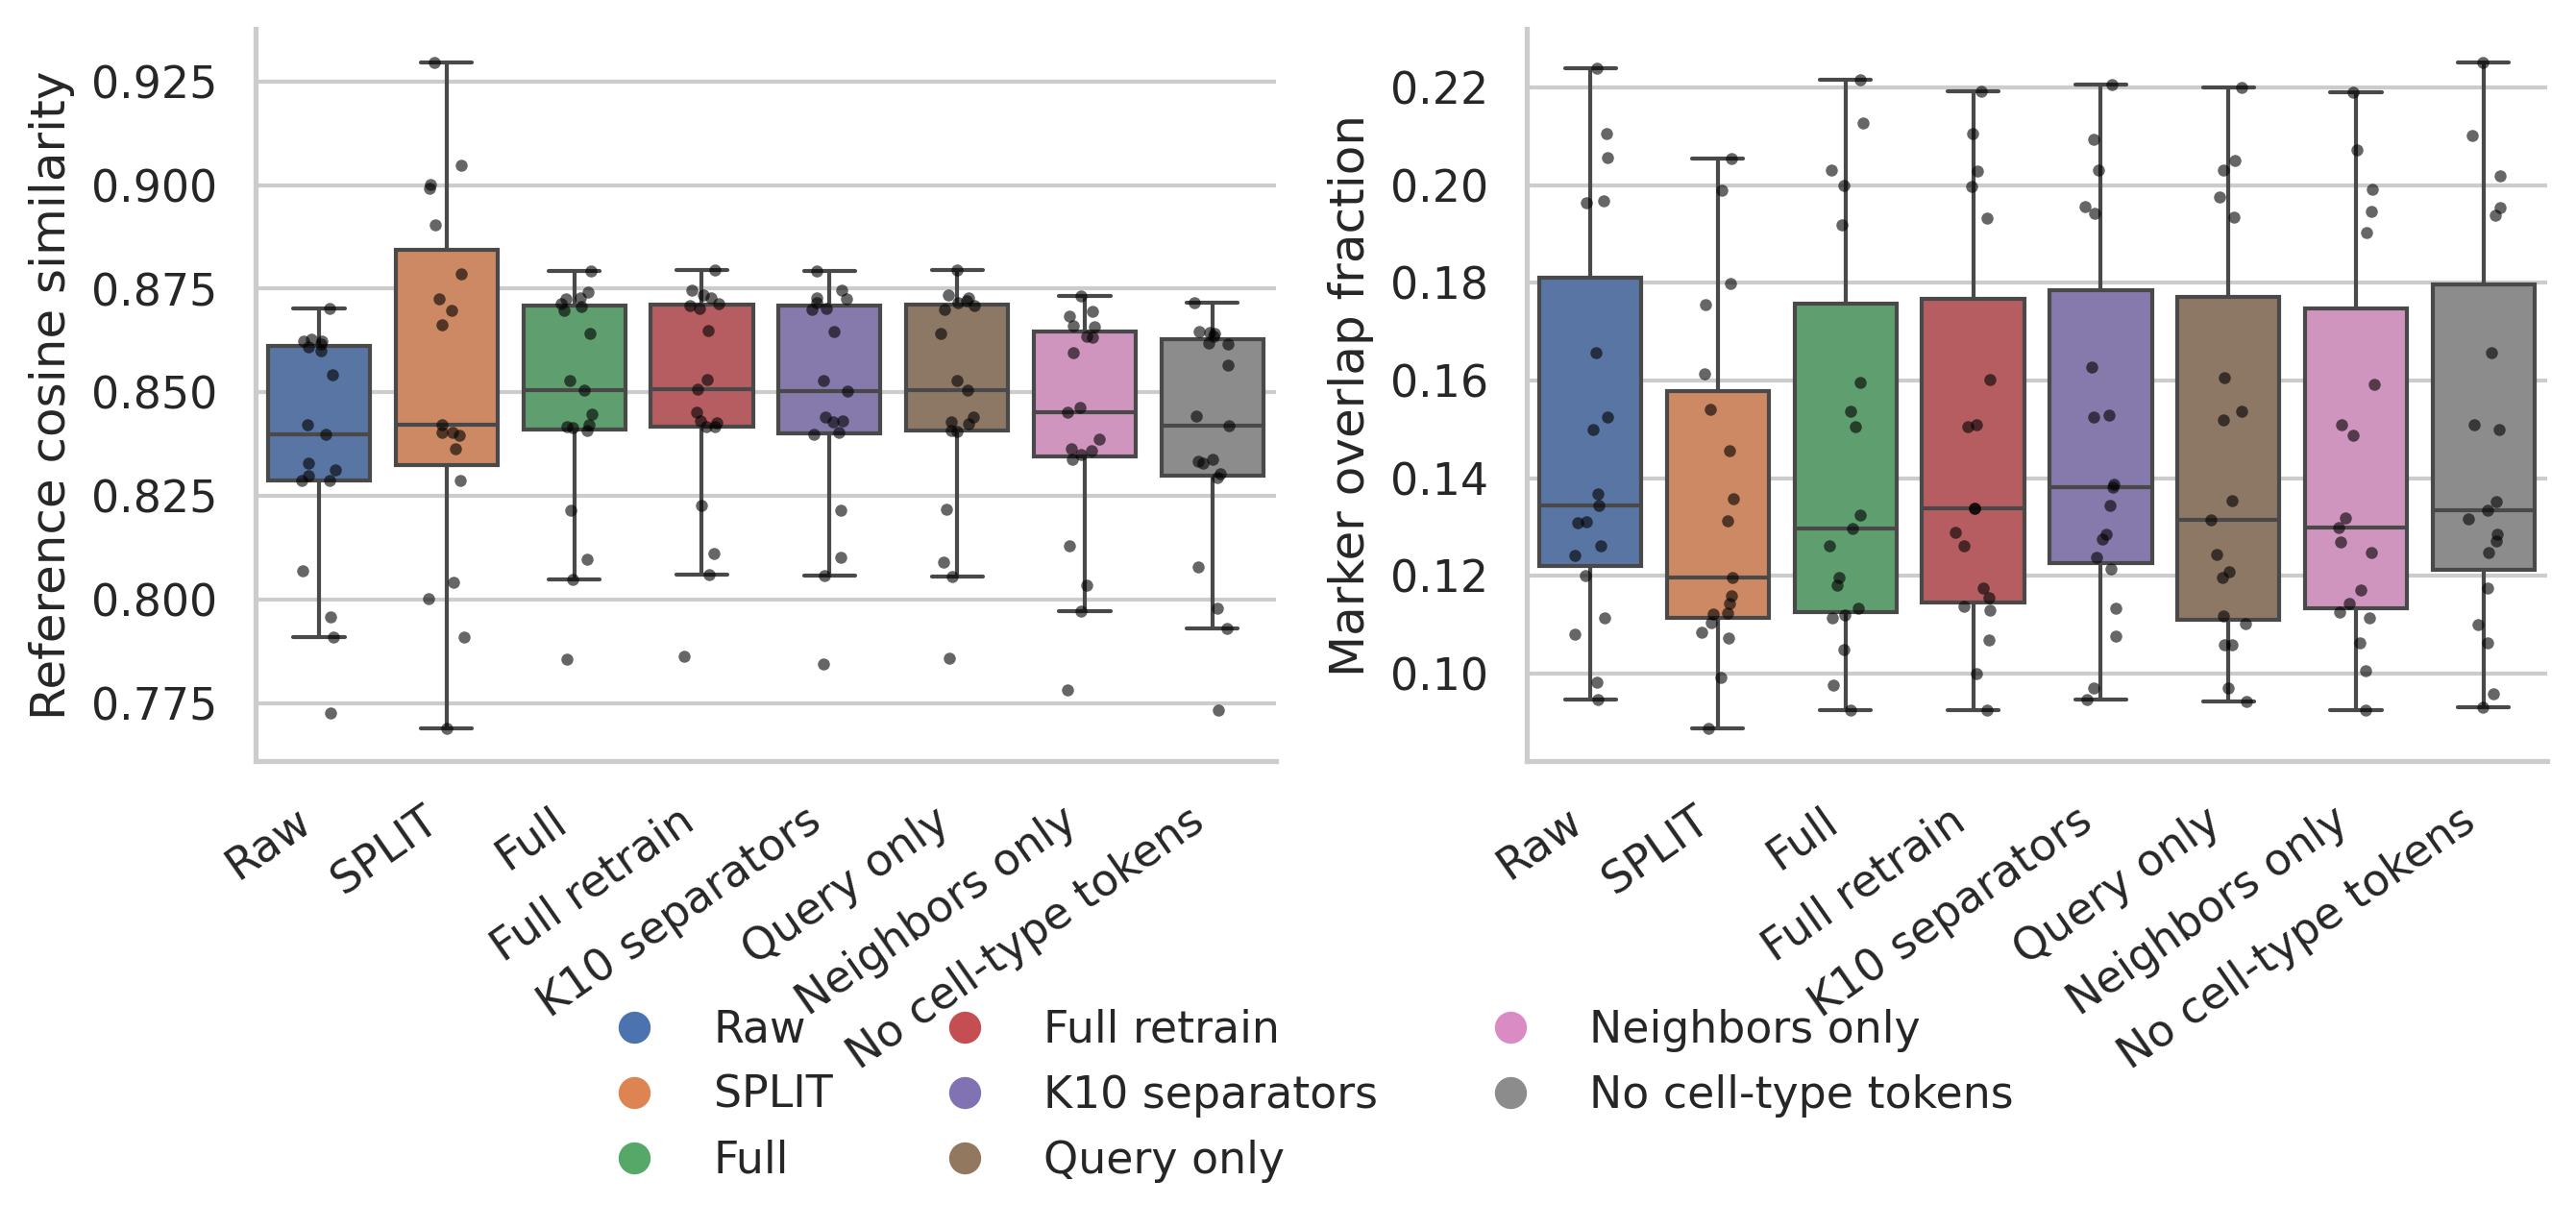

/tmp/ipykernel_3153997/1949607224.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha='right')
/tmp/ipykernel_3153997/1949607224.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha='right')


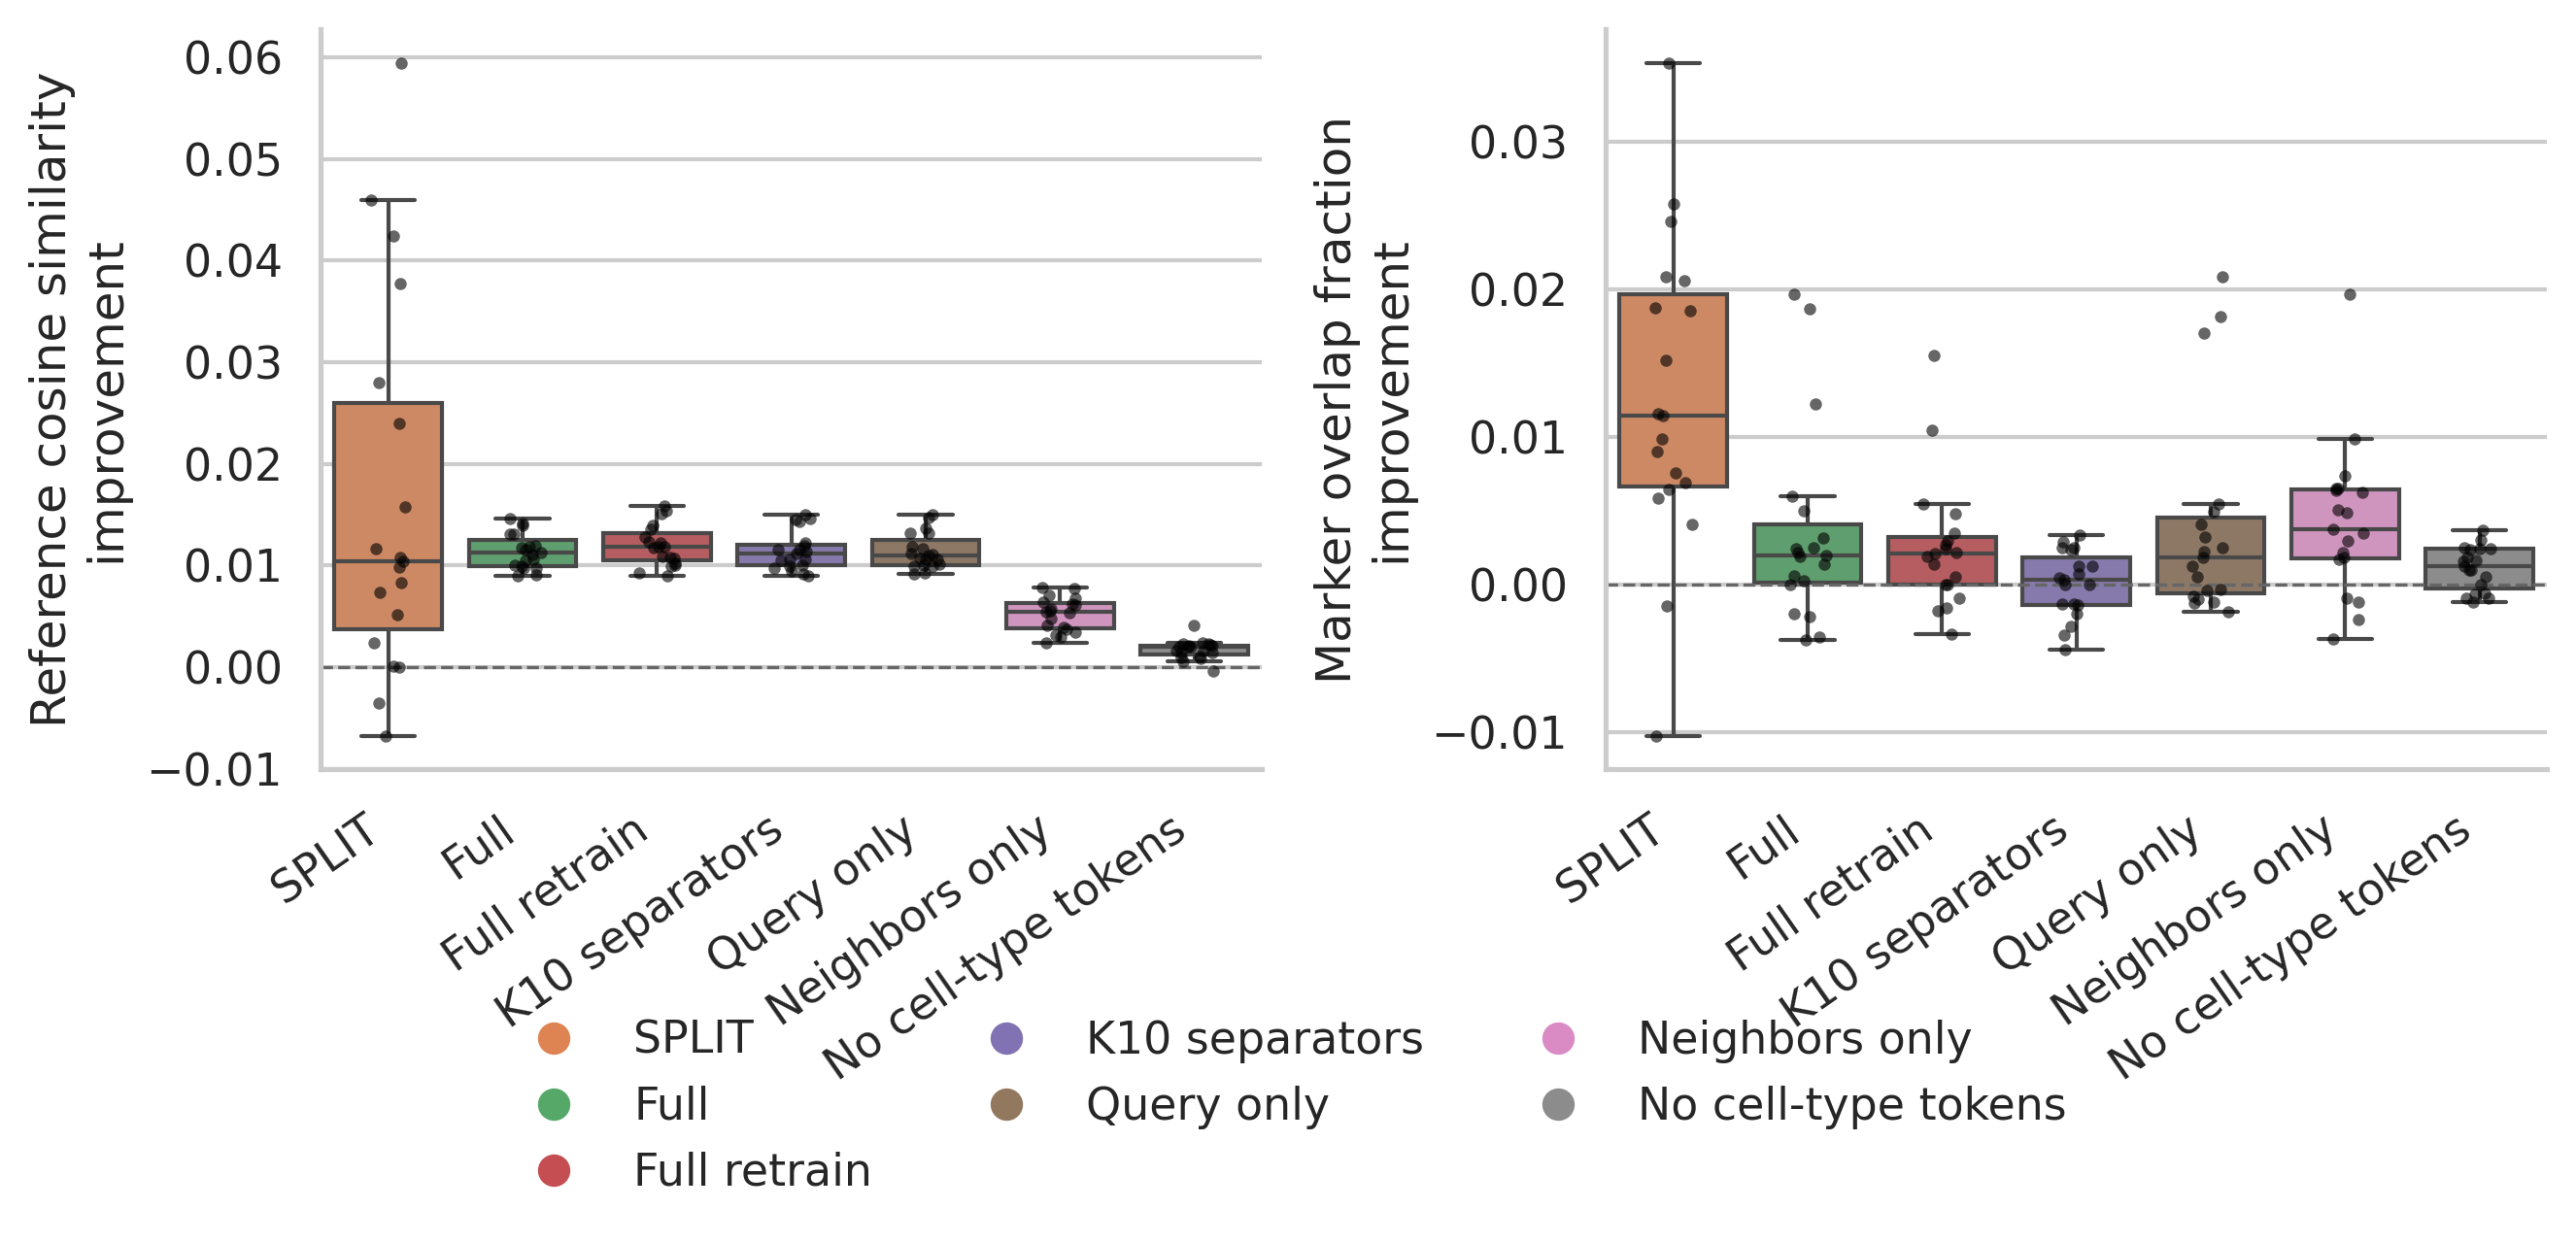

In [20]:
def prepare_tcell(filename, value_col, pair_cols, metric, direction):
    parts = [load_csv(model, "tcell", filename) for model in MODEL_ORDER]
    data = assign_method(valid_rows(pd.concat([x for x in parts if not x.empty], ignore_index=True)), "condition")
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    data = data.loc[np.isfinite(data[value_col])]
    original = (data.groupby(["slice", "method"], observed=True)[value_col].mean()
                .rename("value").reset_index().assign(metric=metric))
    values = data.pivot_table(index=["slice", *pair_cols], columns="method",
                              values=value_col, aggfunc="mean")
    delta = []
    for method in CLEANED_ORDER:
        if "Raw" in values and method in values:
            delta.append(((values[method] - values["Raw"]) * direction)
                         .rename("delta").reset_index().assign(method=method, metric=metric))
    return original, pd.concat(delta, ignore_index=True)

cos_o, cos_d = prepare_tcell(
    "tcell_cosine_similarity.csv", "cosine_similarity",
    ["spatial_cell_type", "reference_cell_type"], "Reference cosine similarity", 1,
)
con_o, con_d = prepare_tcell(
    "tcell_contamination_metrics.csv", "marker_overlap_frac",
    ["target_cell_type_i", "contaminating_cell_type_j"], "Marker overlap fraction", -1,
)
tcell_original = pd.concat([cos_o, con_o], ignore_index=True)
tcell_delta = (pd.concat([cos_d, con_d], ignore_index=True)
               .groupby(["slice", "method", "metric"], observed=True)["delta"].mean().reset_index())
TCELL_METRICS = ["Reference cosine similarity", "Marker overlap fraction"]
print(tcell_original.groupby("method")["slice"].nunique().reindex(COUNT_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), squeeze=False, dpi=300)
for ax, metric in zip(axes.flat, TCELL_METRICS):
    subset = tcell_original.loc[tcell_original["metric"].eq(metric)]
    sns.boxplot(data=subset, x="method", y="value", hue="method", order=COUNT_ORDER,
                hue_order=COUNT_ORDER, palette=COLORS, legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=subset, x="method", y="value", order=COUNT_ORDER,
                  color="black", size=3, alpha=.6, jitter=.14, ax=ax)
    ax.set(xlabel="", ylabel=metric)
    ax.tick_params(axis="x", rotation=32)
    ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha='right')
    ax.grid(axis="x", visible=False)
fig.legend(handles=handles(COUNT_ORDER), loc="lower center", ncol=3,
           bbox_to_anchor=(.5, -.08), frameon=False)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4), squeeze=False, dpi=300)
for ax, metric in zip(axes.flat, TCELL_METRICS):
    subset = tcell_delta.loc[tcell_delta["metric"].eq(metric)]
    sns.boxplot(data=subset, x="method", y="delta", hue="method", order=CLEANED_ORDER,
                hue_order=CLEANED_ORDER, palette=COLORS, legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=subset, x="method", y="delta", order=CLEANED_ORDER,
                  color="black", size=3, alpha=.6, jitter=.14, ax=ax)
    ax.axhline(0, color="#666666", linestyle="--", linewidth=.8)
    ax.set(xlabel="", ylabel=f"{metric}\nimprovement")
    ax.tick_params(axis="x", rotation=32)
    ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha='right')
    ax.grid(axis="x", visible=False)
fig.legend(handles=handles(CLEANED_ORDER), loc="lower center", ncol=3,
           bbox_to_anchor=(.5, -.08), frameon=False)
fig.tight_layout()
plt.show()


## Expression retained after cleaning


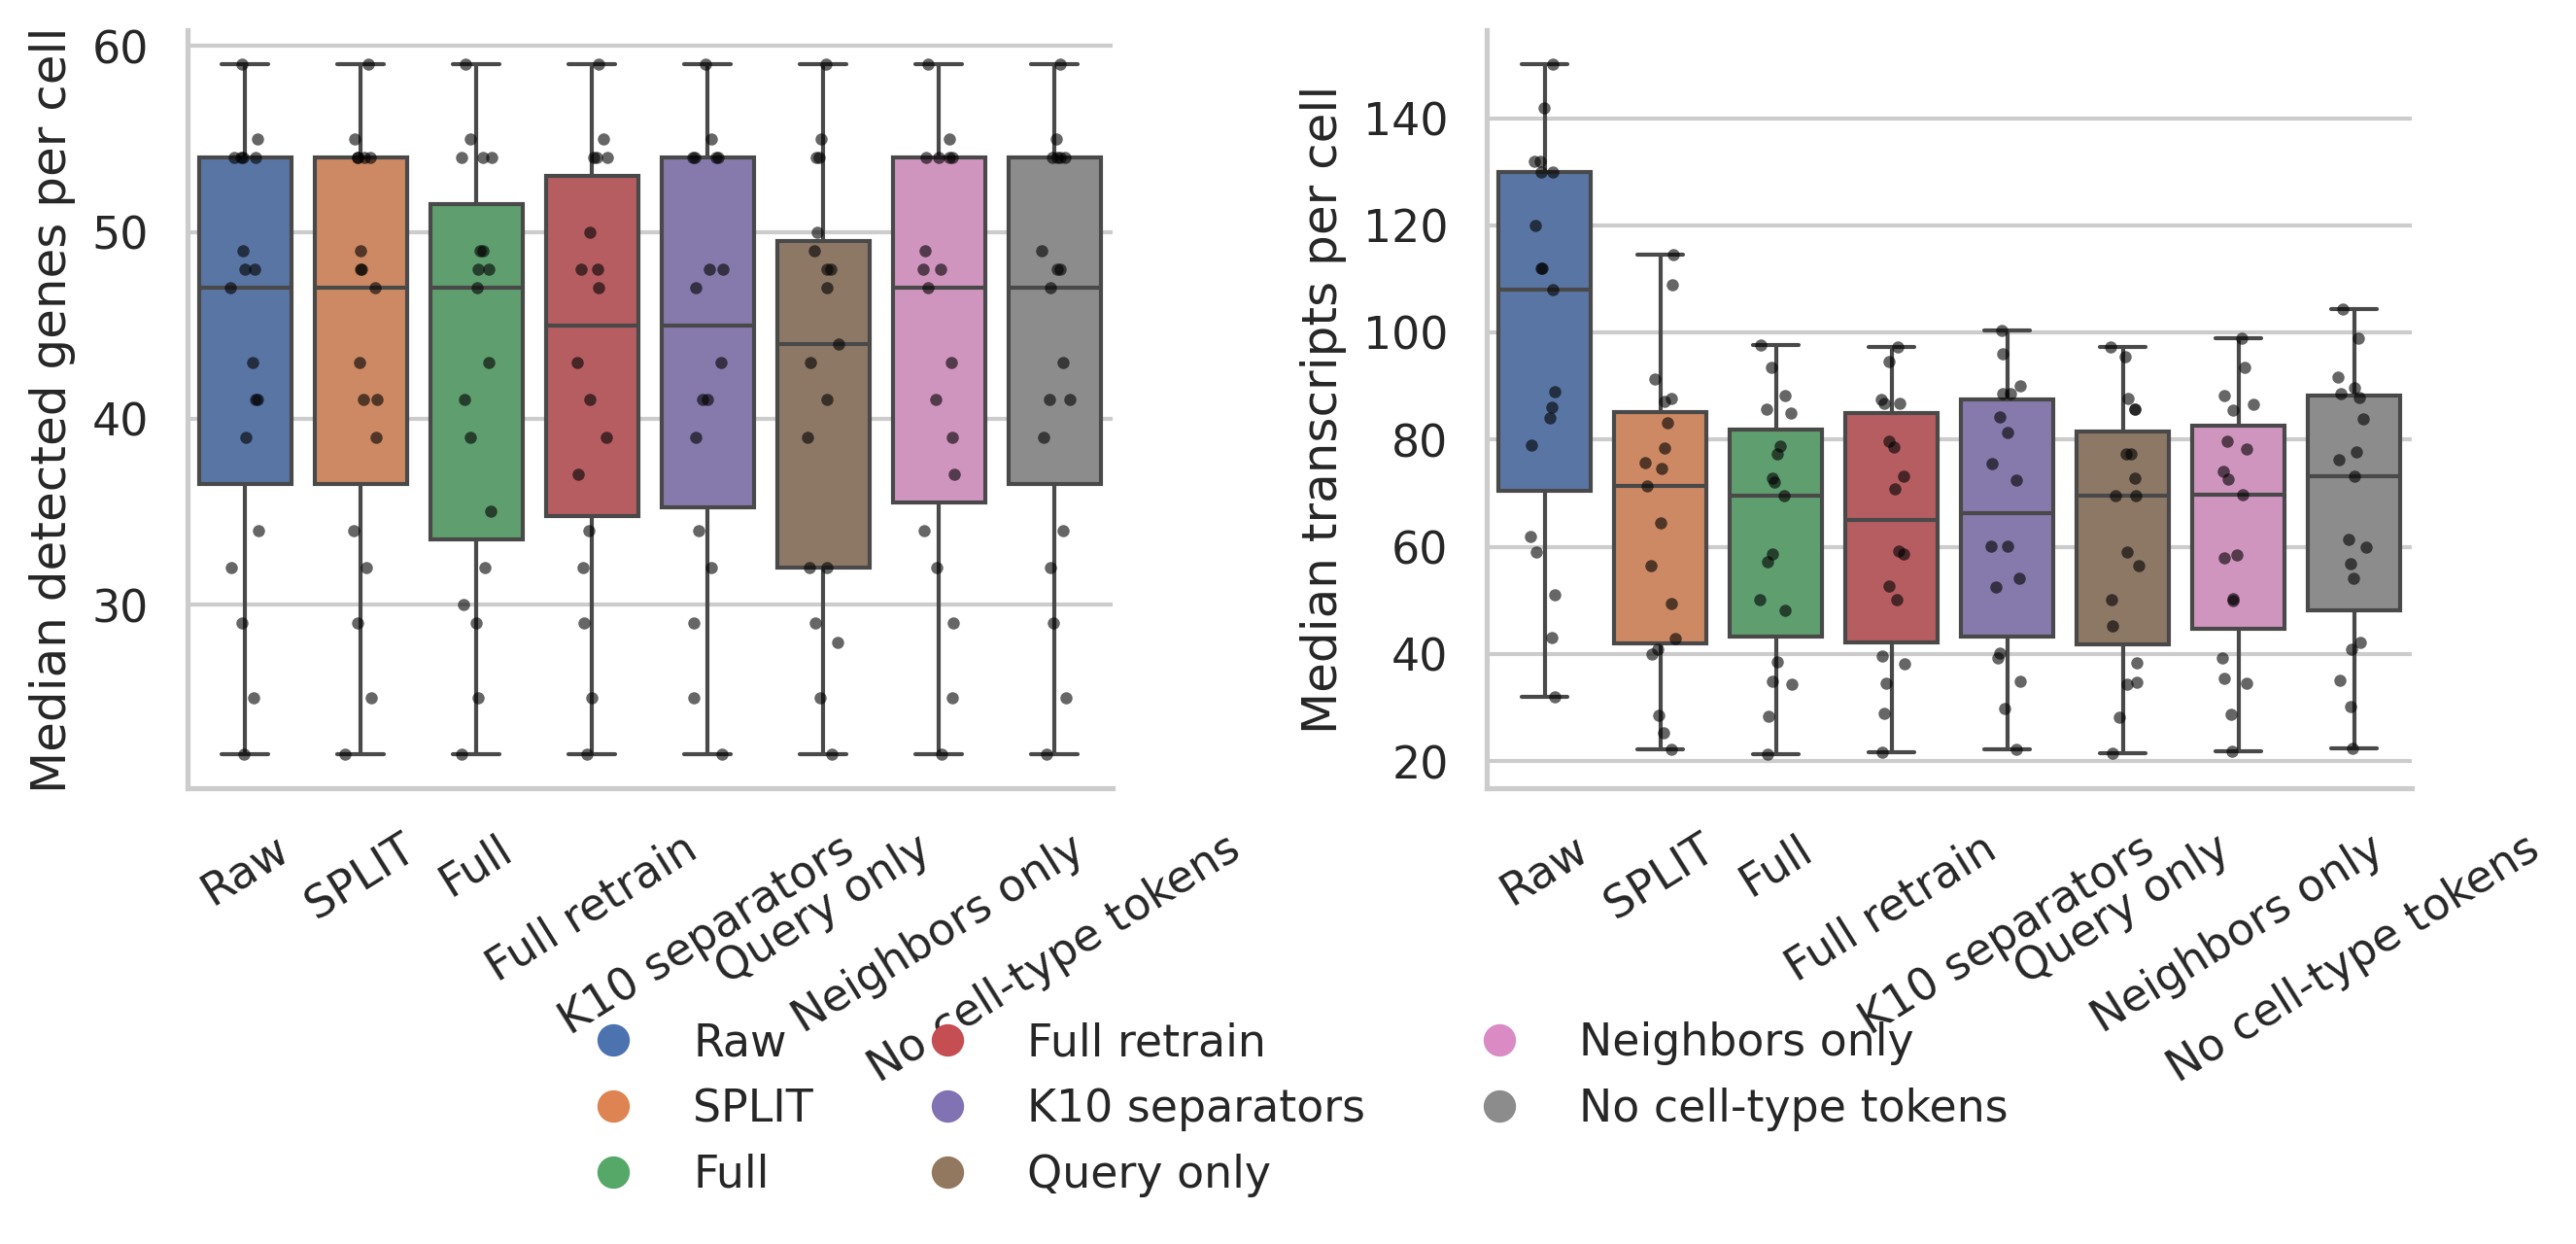

In [7]:
COUNT_METRICS = OrderedDict({
    "median_genes_per_cell": "Median detected genes per cell",
    "median_transcripts_per_cell": "Median transcripts per cell",
})
count_data = non_tcell[["slice", "method", *COUNT_METRICS]].copy()
fig, axes = plt.subplots(1, 2, figsize=(9, 4), squeeze=False, dpi=300)
for ax, (metric, label) in zip(axes.flat, COUNT_METRICS.items()):
    subset = count_data.dropna(subset=[metric])
    sns.boxplot(data=subset, x="method", y=metric, hue="method", order=COUNT_ORDER,
                hue_order=COUNT_ORDER, palette=COLORS, legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=subset, x="method", y=metric, order=COUNT_ORDER,
                  color="black", size=3, alpha=.6, jitter=.14, ax=ax)
    ax.set(xlabel="", ylabel=label)
    ax.tick_params(axis="x", rotation=32)
    ax.grid(axis="x", visible=False)
fig.legend(handles=handles(COUNT_ORDER), loc="lower center", ncol=3,
           bbox_to_anchor=(.5, -.08), frameon=False)
fig.tight_layout()
plt.show()


## Available plot tables

The slice-level tables are `non_tcell_original`, `non_tcell_delta`, `non_tcell_percent`, `syndri_best_scatter`, `tcell_original`, `tcell_delta`, and `count_data`.
